# Цель работы

Исследование влияния различных методов уменьшения размерности (PCA, Isomap, t-SNE, UMAP) на качество кластеризации, оцененное с помощью внутренних метрик (Silhouette Score, Calinski–Harabasz Index, Davies–Bouldin Index) и внешних метрик (при наличии разметки)



# Теоретическая часть
## Методы уменьшения размерности (Dimensionality Reduction - DR)
+ PCA (Principal Component Analysis):

   + Линейный метод, максимизирующий дисперсию данных

   + Сохраняет глобальную структуру данных

   + Вычислительно эффективен

+ Isomap (Isometric Mapping):

   + Нелинейный метод, сохраняющий геодезические расстояния

   + Основан на многомерном шкалировании (MDS)

   + Эффективен для данных с нелинейной структурой

+ t-SNE (t-distributed Stochastic Neighbor Embedding):

   + Вероятностный метод, сохраняющий локальную структуру

   + Эффективен для визуализации

   + Вычислительно сложен для больших данных

+ UMAP (Uniform Manifold Approximation and Projection):

   + Основан на теории топологических пространств

   + Сохражает как локальную, так и глобальную структуру

   + Вычислительно эффективнее t-SNE

## Метрики кластеризации
+ Внутренние метрики:
   + Silhouette Score: Мера компактности и разделимости кластеров

   + Calinski–Harabasz Index: Отношение дисперсии между кластерами к дисперсии внутри кластеров

   + Davies–Bouldin Index: Среднее сходство между кластерами

+ Внешние метрики:
   + Adjusted Rand Index (ARI)

   + Adjusted Mutual Information (AMI)

   + Homogeneity, Completeness, V-measure

# Задание 1: Подготовка данных и реализация DR-методов

In [1]:
import os
import sys
import time
import warnings
from itertools import combinations
from pathlib import Path

numba_cache = Path(".numba_cache").resolve()
numba_cache.mkdir(exist_ok=True)
os.environ["NUMBA_CACHE_DIR"] = str(numba_cache)
os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count() or 1)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, load_wine
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.manifold import Isomap, TSNE, trustworthiness
from sklearn.cluster import (
    KMeans, AgglomerativeClustering, DBSCAN,
    OPTICS, SpectralClustering, Birch
)
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, adjusted_mutual_info_score,
    homogeneity_score, completeness_score, v_measure_score
)
# ParametricUMAP не используется; исключаем загрузку необязательного TensorFlow-стека.
sys.modules["tensorflow"] = None
from umap import UMAP

warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("tab10")
RANDOM_STATE = 42

,Датасет,Объекты,Признаки,Классы,Пропуски после обработки
0,Iris,150,4,3,0
1,Wine,178,13,3,0
2,Mice,1080,77,8,0


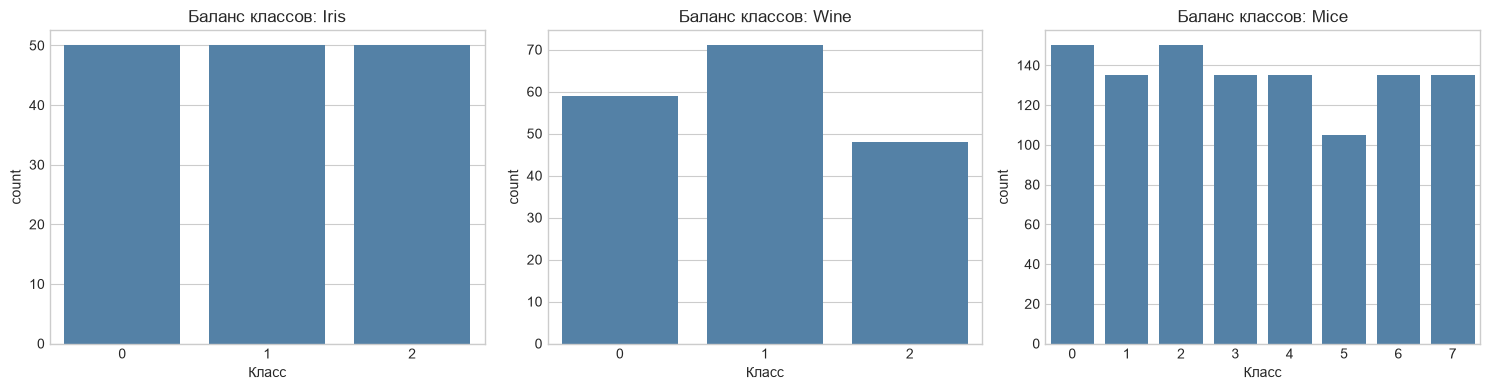

In [2]:
def load_datasets():
    """Загрузка двух учебных наборов и пользовательского набора Mice."""
    iris = load_iris()
    wine = load_wine()

    mice_path = Path("../lab4/Data_Cortex_Nuclear.xls")
    if not mice_path.exists():
        mice_path = Path("clustering/lab4/Data_Cortex_Nuclear.xls")
    mice = pd.read_excel(mice_path)
    protein_cols = mice.select_dtypes(include="number").columns.tolist()
    X_mice = SimpleImputer(strategy="median").fit_transform(mice[protein_cols])
    y_mice = LabelEncoder().fit_transform(mice["class"])

    return {
        "Iris": (iris.data, iris.target, iris.feature_names),
        "Wine": (wine.data, wine.target, wine.feature_names),
        "Mice": (X_mice, y_mice, protein_cols),
    }


datasets = load_datasets()
dataset_info = pd.DataFrame([
    {"Датасет": name, "Объекты": X.shape[0], "Признаки": X.shape[1],
     "Классы": np.unique(y).size, "Пропуски после обработки": int(np.isnan(X).sum())}
    for name, (X, y, _) in datasets.items()
])
display(dataset_info)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, (_, y, _)) in zip(axes, datasets.items()):
    sns.countplot(x=y, ax=ax, color="steelblue")
    ax.set_title(f"Баланс классов: {name}")
    ax.set_xlabel("Класс")
plt.tight_layout()
plt.show()

C:\Users\1\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\1\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


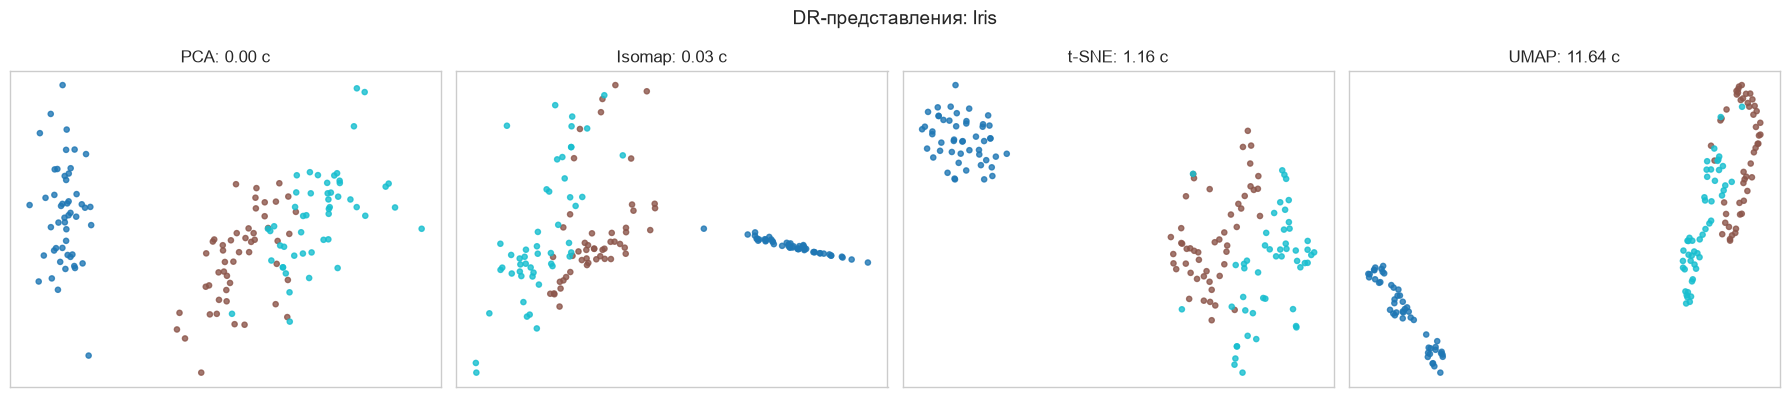

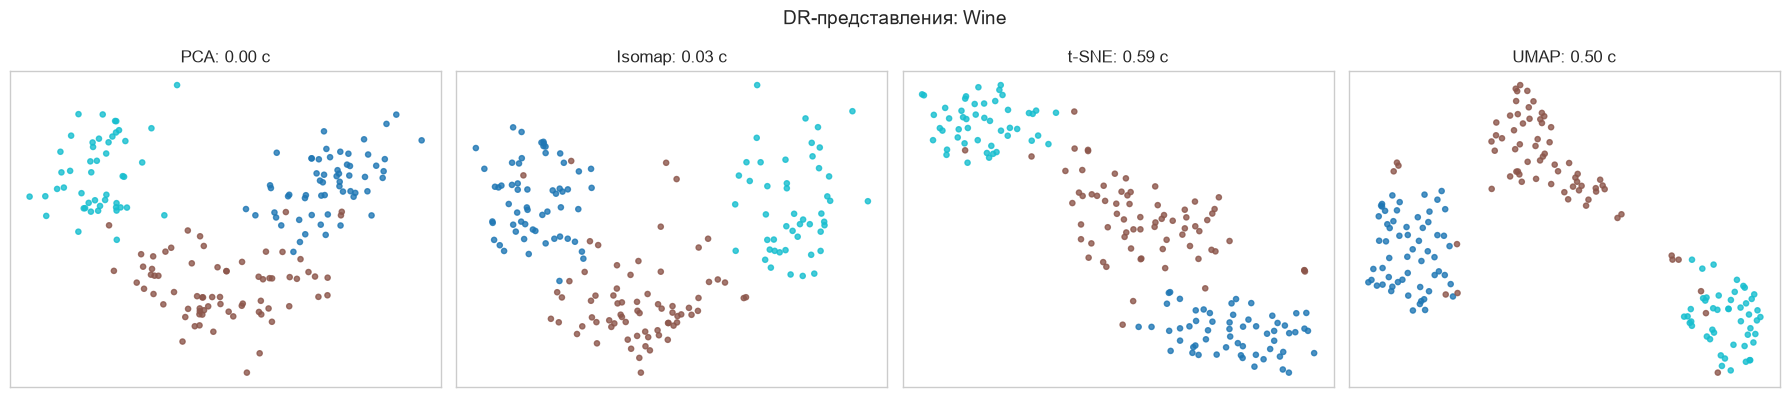

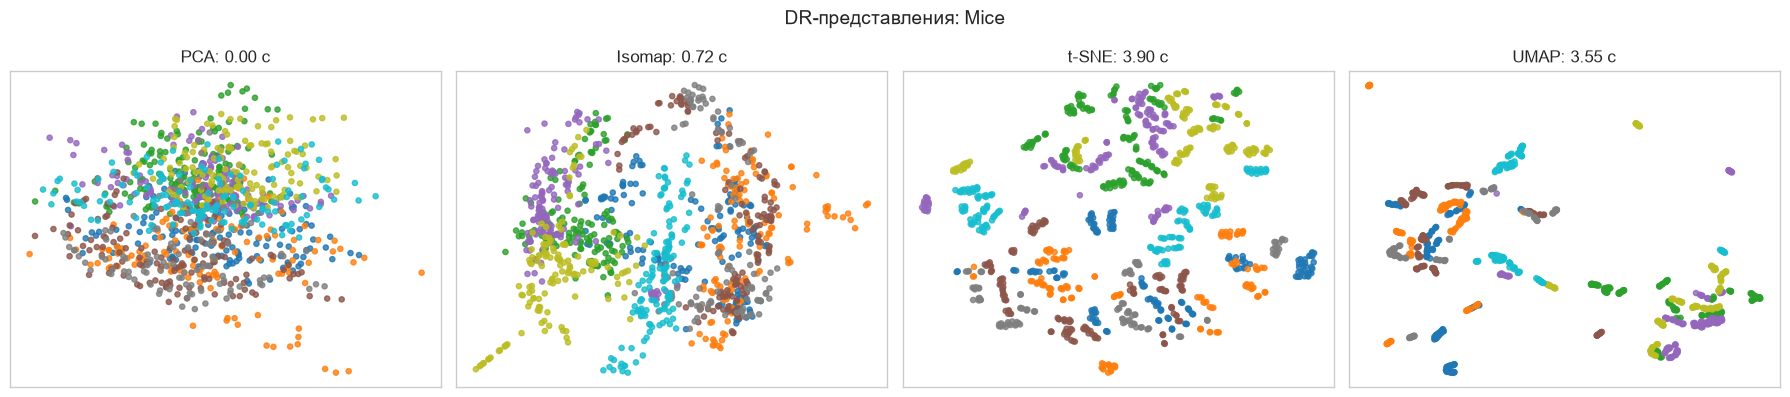

,Датасет,DR,Время_DR_с,Trustworthiness@10
0,Iris,PCA,0.004,0.978
1,Iris,Isomap,0.033,0.969
2,Iris,t-SNE,1.163,0.986
3,Iris,UMAP,11.640,0.975
4,Wine,PCA,0.001,0.888
5,Wine,Isomap,0.025,0.880
6,Wine,t-SNE,0.587,0.956
7,Wine,UMAP,0.496,0.951
8,Mice,PCA,0.005,0.841
9,Mice,Isomap,0.718,0.834


In [3]:
def reduce_dimensions(X, method, **params):
    """Масштабирование и переход к двум компонентам выбранным DR-методом."""
    X_scaled = StandardScaler().fit_transform(X)
    start = time.perf_counter()
    if method == "Original":
        embedding = X_scaled
    elif method == "PCA":
        embedding = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_scaled)
    elif method == "Isomap":
        embedding = Isomap(n_components=2, n_neighbors=params.get("n_neighbors", 10)).fit_transform(X_scaled)
    elif method == "t-SNE":
        embedding = TSNE(
            n_components=2, perplexity=params.get("perplexity", 30),
            learning_rate="auto", init="pca", random_state=RANDOM_STATE
        ).fit_transform(X_scaled)
    elif method == "UMAP":
        embedding = UMAP(
            n_components=2, n_neighbors=params.get("n_neighbors", 15),
            min_dist=params.get("min_dist", 0.1), random_state=RANDOM_STATE,
            n_jobs=1
        ).fit_transform(X_scaled)
    else:
        raise ValueError(f"Неизвестный метод: {method}")
    elapsed = time.perf_counter() - start
    local_trust = np.nan if method == "Original" else trustworthiness(
        X_scaled, embedding, n_neighbors=min(10, len(X_scaled) // 2 - 1)
    )
    return embedding, elapsed, local_trust


dr_methods = ["Original", "PCA", "Isomap", "t-SNE", "UMAP"]
representations = {}
dr_rows = []

for dataset_name, (X, y, _) in datasets.items():
    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    for ax, method in zip(axes, dr_methods[1:]):
        embedding, elapsed, local_trust = reduce_dimensions(X, method)
        representations[(dataset_name, method)] = embedding
        dr_rows.append([dataset_name, method, elapsed, local_trust])
        scatter = ax.scatter(embedding[:, 0], embedding[:, 1], c=y, s=14, cmap="tab10", alpha=0.8)
        ax.set_title(f"{method}: {elapsed:.2f} с")
        ax.set_xticks([]); ax.set_yticks([])
    representations[(dataset_name, "Original")] = StandardScaler().fit_transform(X)
    fig.suptitle(f"DR-представления: {dataset_name}", fontsize=14)
    plt.tight_layout(); plt.show()

dr_results = pd.DataFrame(dr_rows, columns=["Датасет", "DR", "Время_DR_с", "Trustworthiness@10"])
display(dr_results.style.format({"Время_DR_с": "{:.3f}", "Trustworthiness@10": "{:.3f}"}))

# Задание 2: Реализация системы оценки кластеризации

In [4]:
class ClusteringEvaluator:
    """Расчёт внутренних и внешних метрик с корректной обработкой шума."""
    @staticmethod
    def evaluate(X, labels, y_true, algorithm, dr_method, elapsed=0.0):
        labels = np.asarray(labels)
        mask = labels != -1
        clustered_labels = labels[mask]
        n_clusters = np.unique(clustered_labels).size
        valid_internal = mask.sum() > n_clusters > 1

        row = {
            "DR": dr_method,
            "Алгоритм": algorithm,
            "Кластеров": n_clusters,
            "Шум_%": 100 * np.mean(~mask),
            "Время_с": elapsed,
            "Silhouette": np.nan,
            "Calinski_Harabasz": np.nan,
            "Davies_Bouldin": np.nan,
            "ARI": adjusted_rand_score(y_true, labels),
            "AMI": adjusted_mutual_info_score(y_true, labels),
            "Homogeneity": homogeneity_score(y_true, labels),
            "Completeness": completeness_score(y_true, labels),
            "V_measure": v_measure_score(y_true, labels),
        }
        if valid_internal:
            row["Silhouette"] = silhouette_score(X[mask], clustered_labels)
            row["Calinski_Harabasz"] = calinski_harabasz_score(X[mask], clustered_labels)
            row["Davies_Bouldin"] = davies_bouldin_score(X[mask], clustered_labels)
        return row


def cluster_predict(name, X, n_clusters, seed=RANDOM_STATE):
    if name == "KMeans":
        model = KMeans(n_clusters=n_clusters, n_init=20, random_state=seed)
    elif name == "Agglomerative":
        model = AgglomerativeClustering(n_clusters=n_clusters, linkage="ward")
    elif name == "GMM":
        return GaussianMixture(n_components=n_clusters, n_init=5, random_state=seed).fit_predict(X)
    elif name == "DBSCAN":
        # eps определяется относительно масштаба конкретного представления.
        distances = np.linalg.norm(X - np.median(X, axis=0), axis=1)
        model = DBSCAN(eps=max(np.quantile(distances, 0.35) * 0.35, 0.1), min_samples=8)
    else:
        raise ValueError(name)
    return model.fit_predict(X)

# Задание 3: Сравнение алгоритмов на различных DR-представлениях

In [5]:
def compare_clustering_on_dr(dataset_name, algorithms=("KMeans", "Agglomerative", "GMM", "DBSCAN")):
    X_original, y_true, _ = datasets[dataset_name]
    n_clusters = np.unique(y_true).size
    rows = []
    for method in dr_methods:
        X_dr = representations[(dataset_name, method)]
        for algorithm in algorithms:
            start = time.perf_counter()
            labels = cluster_predict(algorithm, X_dr, n_clusters)
            elapsed = time.perf_counter() - start
            row = ClusteringEvaluator.evaluate(X_dr, labels, y_true, algorithm, method, elapsed)
            row["Датасет"] = dataset_name
            rows.append(row)
    return pd.DataFrame(rows)


baseline_results = compare_clustering_on_dr("Mice")
metric_columns = ["Silhouette", "Calinski_Harabasz", "Davies_Bouldin", "ARI", "AMI", "V_measure"]
display(
    baseline_results.sort_values("ARI", ascending=False)
    .style.format({c: "{:.3f}" for c in metric_columns} | {"Время_с": "{:.3f}", "Шум_%": "{:.1f}"})
)

C:\Users\1\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\Users\1\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\Users\1\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\Users\1\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when

,DR,Алгоритм,Кластеров,Шум_%,Время_с,Silhouette,Calinski_Harabasz,Davies_Bouldin,ARI,AMI,Homogeneity,Completeness,V_measure,Датасет
9,Isomap,Agglomerative,8,0.0,0.038,0.393,1100.394,0.770,0.273,0.427,0.425332,0.442953,0.434,Mice
10,Isomap,GMM,8,0.0,0.491,0.392,1078.380,0.773,0.257,0.419,0.415739,0.436802,0.426,Mice
8,Isomap,KMeans,8,0.0,0.303,0.419,1221.985,0.760,0.254,0.418,0.418865,0.430488,0.425,Mice
18,UMAP,GMM,8,0.0,0.347,0.530,1595.289,0.639,0.247,0.429,0.410558,0.465379,0.436,Mice
12,t-SNE,KMeans,8,0.0,0.260,0.430,1298.104,0.772,0.245,0.427,0.430755,0.435423,0.433,Mice
13,t-SNE,Agglomerative,8,0.0,0.032,0.412,1186.956,0.788,0.238,0.409,0.409110,0.422407,0.416,Mice
16,UMAP,KMeans,8,0.0,0.271,0.466,1772.731,0.694,0.225,0.406,0.392003,0.436924,0.413,Mice
14,t-SNE,GMM,8,0.0,0.283,0.386,1128.982,0.804,0.222,0.404,0.403851,0.417550,0.411,Mice
17,UMAP,Agglomerative,8,0.0,0.038,0.467,1609.721,0.715,0.204,0.388,0.372353,0.420843,0.395,Mice
2,Original,GMM,8,0.0,1.108,0.122,111.026,1.888,0.143,0.259,0.260686,0.275973,0.268,Mice


# Задание 4: Визуализация и анализ результатов

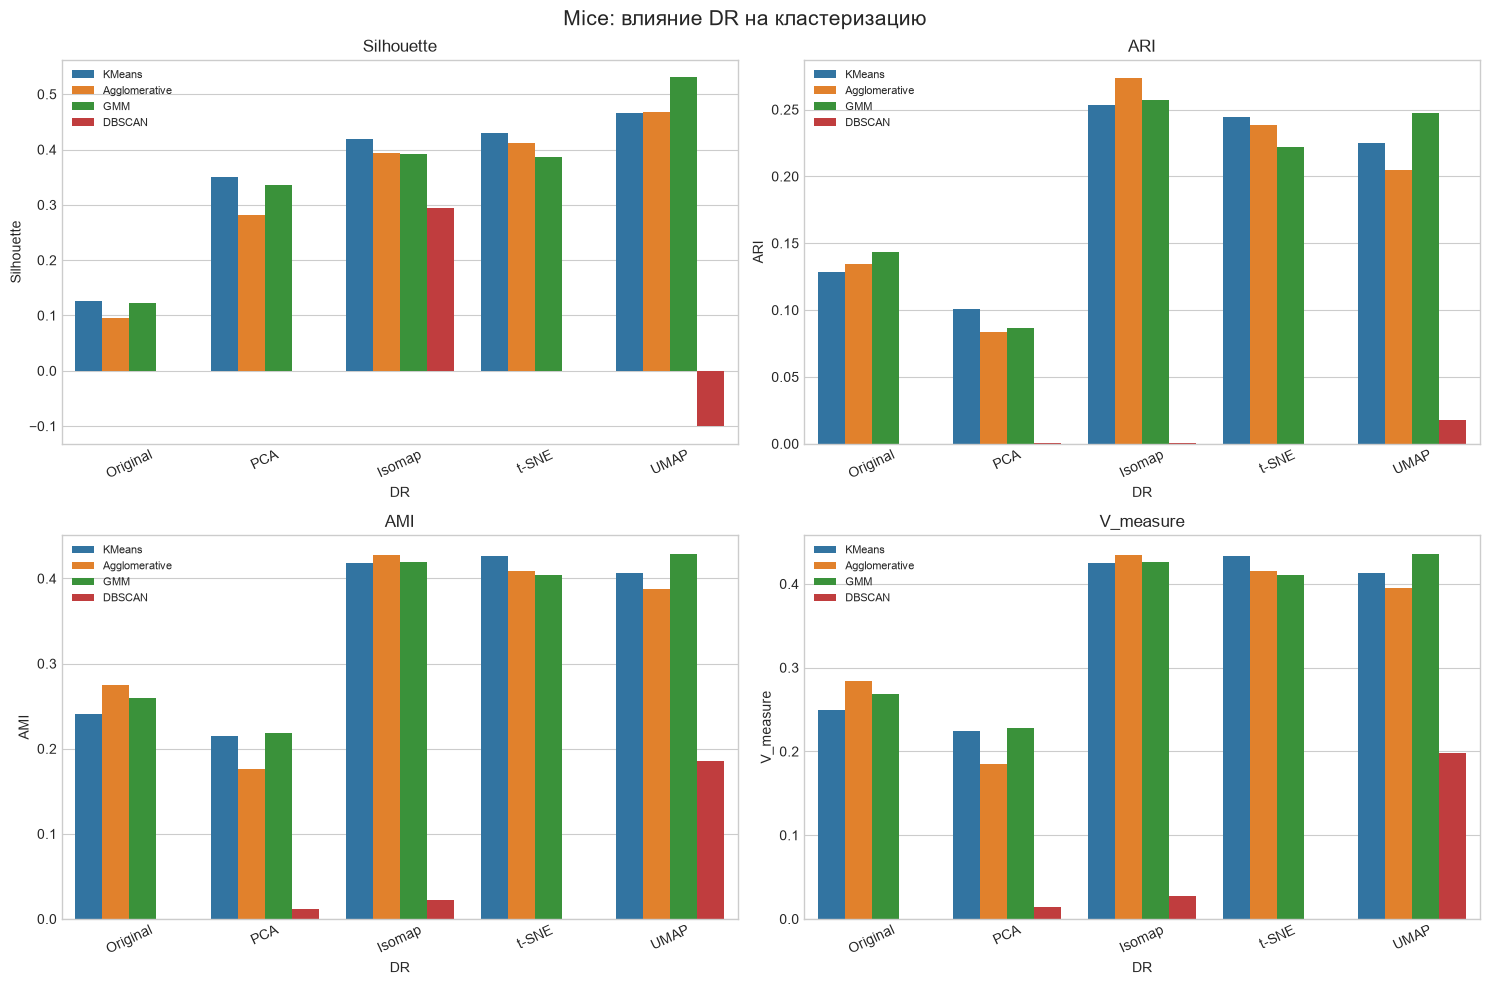

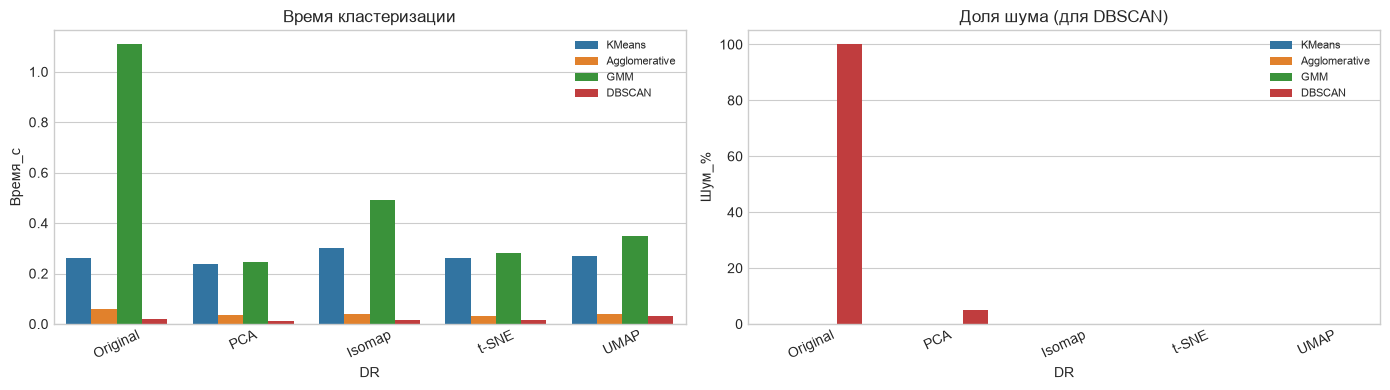

In [6]:
def visualize_metrics_comparison(results, title):
    plot_metrics = ["Silhouette", "ARI", "AMI", "V_measure"]
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    for ax, metric in zip(axes.ravel(), plot_metrics):
        sns.barplot(data=results, x="DR", y=metric, hue="Алгоритм", ax=ax, errorbar=None)
        ax.set_title(metric)
        ax.tick_params(axis="x", rotation=25)
        ax.legend(fontsize=8)
    fig.suptitle(title, fontsize=15)
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.barplot(data=results, x="DR", y="Время_с", hue="Алгоритм", ax=axes[0], errorbar=None)
    axes[0].set_title("Время кластеризации")
    sns.barplot(data=results, x="DR", y="Шум_%", hue="Алгоритм", ax=axes[1], errorbar=None)
    axes[1].set_title("Доля шума (для DBSCAN)")
    for ax in axes:
        ax.tick_params(axis="x", rotation=25); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()


visualize_metrics_comparison(baseline_results, "Mice: влияние DR на кластеризацию")

# Задание 5: Статистический анализ и выводы

In [7]:
def perform_statistical_analysis(results):
    print("Лучшие комбинации по метрикам")
    directions = {
        "Silhouette": False, "Calinski_Harabasz": False,
        "Davies_Bouldin": True, "ARI": False, "AMI": False, "V_measure": False
    }
    best_rows = []
    for metric, ascending in directions.items():
        valid = results.dropna(subset=[metric]).sort_values(metric, ascending=ascending)
        if len(valid):
            row = valid.iloc[0]
            best_rows.append({"Метрика": metric, "DR": row["DR"],
                              "Алгоритм": row["Алгоритм"], "Значение": row[metric]})
    display(pd.DataFrame(best_rows).style.format({"Значение": "{:.3f}"}))

    print("Средние внешние метрики по DR-методам")
    display(results.groupby("DR")[["ARI", "AMI", "V_measure"]].mean().sort_values("ARI", ascending=False).round(3))
    print("Средние внешние метрики по алгоритмам")
    display(results.groupby("Алгоритм")[["ARI", "AMI", "V_measure"]].mean().sort_values("ARI", ascending=False).round(3))


perform_statistical_analysis(baseline_results)

Лучшие комбинации по метрикам


,Метрика,DR,Алгоритм,Значение
0,Silhouette,UMAP,GMM,0.530
1,Calinski_Harabasz,UMAP,KMeans,1772.731
2,Davies_Bouldin,Isomap,DBSCAN,0.575
3,ARI,Isomap,Agglomerative,0.273
4,AMI,UMAP,GMM,0.429
5,V_measure,UMAP,GMM,0.436


Средние внешние метрики по DR-методам


,ARI,AMI,V_measure
DR,,,
Isomap,0.196,0.322,0.328
t-SNE,0.176,0.310,0.315
UMAP,0.174,0.352,0.361
Original,0.102,0.194,0.200
PCA,0.068,0.155,0.163


Средние внешние метрики по алгоритмам


,ARI,AMI,V_measure
Алгоритм,,,
GMM,0.191,0.346,0.354
KMeans,0.191,0.341,0.349
Agglomerative,0.187,0.335,0.343
DBSCAN,0.004,0.044,0.048


# Задание 6: Эксперименты с различными наборами данных

C:\Users\1\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\1\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\1\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\1\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when

,Датасет,DR,Алгоритм,Silhouette,ARI,AMI,V_measure,Время_с
1,Iris,Original,GMM,0.374,0.904,0.898,0.900,0.252
3,Iris,PCA,GMM,0.493,0.689,0.704,0.708,0.075
6,Iris,t-SNE,KMeans,0.634,0.676,0.693,0.697,0.088
9,Iris,UMAP,GMM,0.627,0.644,0.741,0.744,0.064
0,Iris,Original,KMeans,0.460,0.620,0.655,0.659,0.090
2,Iris,PCA,KMeans,0.509,0.620,0.655,0.659,0.088
4,Iris,Isomap,KMeans,0.581,0.612,0.653,0.657,0.085
8,Iris,UMAP,KMeans,0.637,0.612,0.653,0.657,0.095
7,Iris,t-SNE,GMM,0.609,0.561,0.618,0.623,0.105
5,Iris,Isomap,GMM,0.417,0.533,0.618,0.623,0.140


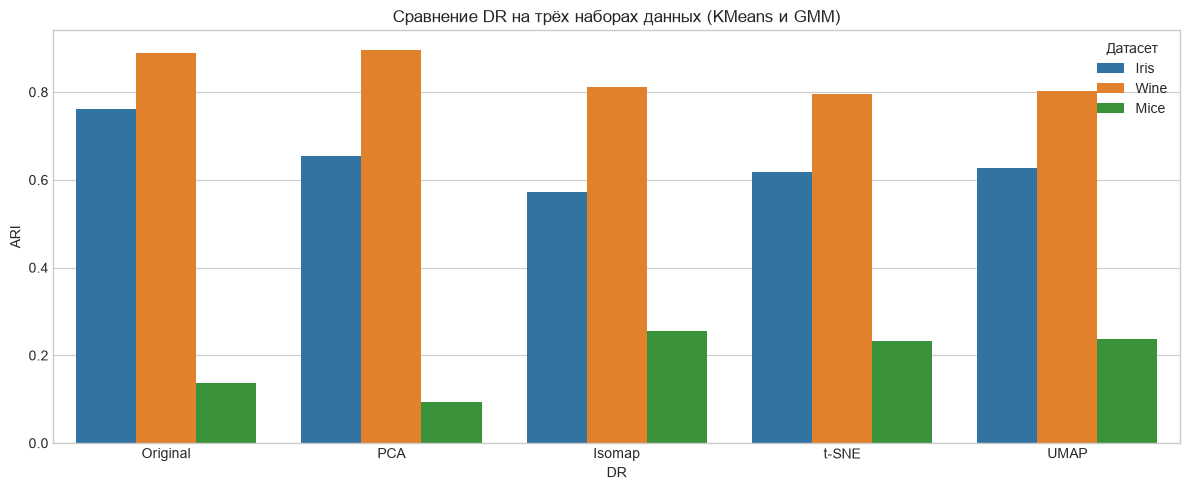

In [8]:
multi_rows = []
for dataset_name, (_, y_true, _) in datasets.items():
    n_clusters = np.unique(y_true).size
    for method in dr_methods:
        X_dr = representations[(dataset_name, method)]
        for algorithm in ("KMeans", "GMM"):
            start = time.perf_counter()
            labels = cluster_predict(algorithm, X_dr, n_clusters)
            elapsed = time.perf_counter() - start
            row = ClusteringEvaluator.evaluate(X_dr, labels, y_true, algorithm, method, elapsed)
            row["Датасет"] = dataset_name
            multi_rows.append(row)

multi_results = pd.DataFrame(multi_rows)
display(
    multi_results.sort_values(["Датасет", "ARI"], ascending=[True, False])
    [["Датасет", "DR", "Алгоритм", "Silhouette", "ARI", "AMI", "V_measure", "Время_с"]]
    .style.format({"Silhouette": "{:.3f}", "ARI": "{:.3f}", "AMI": "{:.3f}",
                   "V_measure": "{:.3f}", "Время_с": "{:.3f}"})
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=multi_results, x="DR", y="ARI", hue="Датасет", errorbar=None, ax=ax)
ax.set_title("Сравнение DR на трёх наборах данных (KMeans и GMM)")
plt.tight_layout(); plt.show()

# Задание для самостоятельной работы
+  Исследование гиперпараметров DR-методов:

   + Изучите влияние параметров каждого DR-метода (n_neighbors для Isomap, perplexity для t-SNE и т.д.)

   + Проведите поиск оптимальных параметров для каждого набора данных

+ Дополнительные алгоритмы кластеризации:

  + Реализуйте и протестируйте OPTICS, Spectral Clustering, BIRCH

  + Сравните их производительность на разных DR-представлениях

+ Анализ устойчивости:

  + Проведите анализ устойчивости результатов к случайным начальным условиям

  + Используйте бутстрап для оценки дисперсии метрик

+ Разработка комплексной оценки:

  + Создайте взвешенную метрику, объединяющую несколько внутренних и внешних метрик

  + Проведите ранжирование комбинаций DR+алгоритм по этой метрике

+ Вопросы для обсуждения:
  + Как выбор метода уменьшения размерности влияет на качество кластеризации?

  + Какие DR-методы лучше сохраняют локальную структуру, а какие - глобальную?

  + Почему t-SNE может давать плохие результаты для кластеризации, несмотря на хорошую визуализацию?

  + Как интерпретировать противоречия между внутренними и внешними метриками?

  + В каких случаях стоит использовать линейные методы (PCA), а в каких - нелинейные (UMAP, t-SNE)?

  + Как время выполнения DR-методов влияет на выбор метода в production-системах?

  + Какие метрики наиболее устойчивы к изменению числа кластеров?

In [9]:
# Основной набор для самостоятельной части — Mice Protein Expression.
X_own, y_own, feature_names_own = datasets["Mice"]
X_own_scaled = StandardScaler().fit_transform(X_own)
n_classes = np.unique(y_own).size
print(f"Mice: {X_own.shape[0]} объектов, {X_own.shape[1]} признаков, {n_classes} классов")

Mice: 1080 объектов, 77 признаков, 8 классов


In [10]:
def evaluate_dr_configuration(dataset_name, method, params):
    X_current, y_current, _ = datasets[dataset_name]
    current_n_classes = np.unique(y_current).size
    embedding, elapsed, local_trust = reduce_dimensions(X_current, method, **params)
    labels = KMeans(n_clusters=current_n_classes, n_init=20, random_state=RANDOM_STATE).fit_predict(embedding)
    row = ClusteringEvaluator.evaluate(embedding, labels, y_current, "KMeans", method)
    row["Датасет"] = dataset_name
    row.update(params)
    row["Время_DR_с"] = elapsed
    row["Trustworthiness@10"] = local_trust
    return embedding, row


hyper_embeddings = {}

## Исследование гиперпараметров DR

C:\Users\1\anaconda3\Lib\site-packages\sklearn\manifold\_isomap.py:386: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
C:\Users\1\anaconda3\Lib\site-packages\scipy\sparse\_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])
C:\Users\1\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\1\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoi

Лучшие конфигурации для каждого набора данных:


,Датасет,Конфигурация,Silhouette,ARI,AMI,V_measure,Trustworthiness@10,Время_DR_с
0,Iris,Isomap n_neighbors=3,0.635,0.706,0.753,0.756,0.947,0.02
32,Mice,Isomap n_neighbors=10,0.419,0.254,0.418,0.425,0.834,0.40
19,Wine,Isomap n_neighbors=40,0.566,0.897,0.875,0.876,0.884,0.03


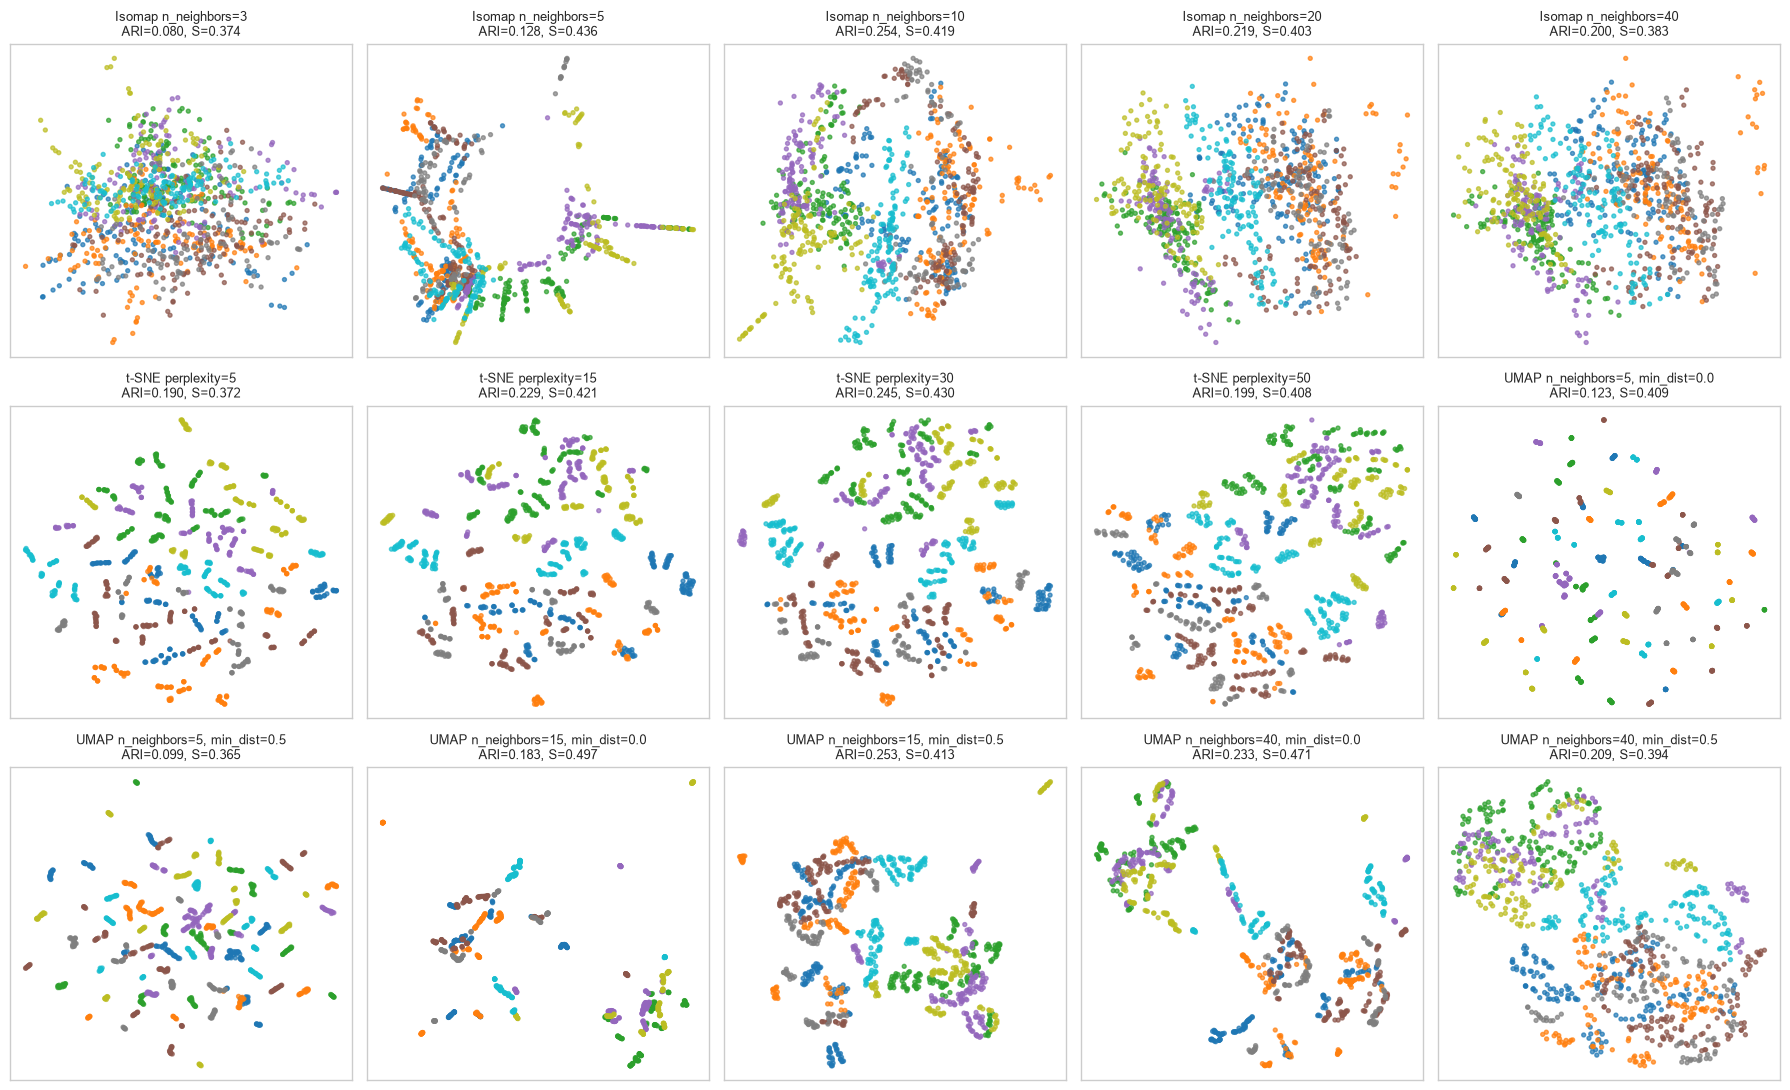

,Датасет,Конфигурация,Silhouette,ARI,AMI,V_measure,Trustworthiness@10,Время_DR_с
0,Iris,Isomap n_neighbors=3,0.635,0.706,0.753,0.756,0.947,0.02
6,Iris,t-SNE perplexity=15,0.598,0.679,0.710,0.714,0.988,0.70
7,Iris,t-SNE perplexity=30,0.634,0.676,0.693,0.697,0.986,0.54
13,Iris,"UMAP n_neighbors=40, min_dist=0.0",0.641,0.664,0.684,0.688,0.978,0.39
5,Iris,t-SNE perplexity=5,0.487,0.652,0.677,0.681,0.982,0.40
3,Iris,Isomap n_neighbors=20,0.560,0.652,0.676,0.680,0.974,0.02
1,Iris,Isomap n_neighbors=5,0.584,0.632,0.667,0.671,0.971,0.01
9,Iris,"UMAP n_neighbors=5, min_dist=0.0",0.641,0.631,0.700,0.704,0.968,0.21
14,Iris,"UMAP n_neighbors=40, min_dist=0.5",0.603,0.620,0.655,0.659,0.976,0.41
2,Iris,Isomap n_neighbors=10,0.581,0.612,0.653,0.657,0.969,0.02


In [11]:
hyper_rows = []
parameter_grid = (
    [("Isomap", {"n_neighbors": value}) for value in [3, 5, 10, 20, 40]] +
    [("t-SNE", {"perplexity": value}) for value in [5, 15, 30, 50]] +
    [("UMAP", {"n_neighbors": n, "min_dist": d})
     for n in [5, 15, 40] for d in [0.0, 0.5]]
)

for dataset_name in datasets:
    for method, params in parameter_grid:
        embedding, row = evaluate_dr_configuration(dataset_name, method, params)
        key = method + " " + ", ".join(f"{k}={v}" for k, v in params.items())
        hyper_embeddings[(dataset_name, key)] = embedding
        row["Конфигурация"] = key
        hyper_rows.append(row)

hyper_results = pd.DataFrame(hyper_rows)
best_hyper = hyper_results.loc[hyper_results.groupby("Датасет")["ARI"].idxmax()]
print("Лучшие конфигурации для каждого набора данных:")
display(best_hyper[["Датасет", "Конфигурация", "Silhouette", "ARI", "AMI", "V_measure", "Trustworthiness@10", "Время_DR_с"]]
        .style.format({"Silhouette": "{:.3f}", "ARI": "{:.3f}", "AMI": "{:.3f}",
                       "V_measure": "{:.3f}", "Trustworthiness@10": "{:.3f}", "Время_DR_с": "{:.2f}"}))

fig, axes = plt.subplots(3, 5, figsize=(18, 11))
for ax, (method, params) in zip(axes.ravel(), parameter_grid):
    key = method + " " + ", ".join(f"{k}={v}" for k, v in params.items())
    embedding = hyper_embeddings[("Mice", key)]
    row = hyper_results[(hyper_results["Датасет"] == "Mice") & (hyper_results["Конфигурация"] == key)].iloc[0]
    ax.scatter(embedding[:, 0], embedding[:, 1], c=y_own, s=8, cmap="tab10", alpha=0.7)
    ax.set_title(f"{key}\nARI={row['ARI']:.3f}, S={row['Silhouette']:.3f}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

display(hyper_results.sort_values(["Датасет", "ARI"], ascending=[True, False])[
    ["Датасет", "Конфигурация", "Silhouette", "ARI", "AMI", "V_measure", "Trustworthiness@10", "Время_DR_с"]
].style.format({"Silhouette": "{:.3f}", "ARI": "{:.3f}", "AMI": "{:.3f}",
                "V_measure": "{:.3f}", "Trustworthiness@10": "{:.3f}", "Время_DR_с": "{:.2f}"}))

## Тестирование дополнительных алгоритмов кластеризации

C:\Users\1\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\Users\1\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\Users\1\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\Users\1\anaconda3\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding ma

,DR,Алгоритм,Кластеров,Шум_%,Silhouette,ARI,AMI,V_measure,Время_с
11,t-SNE,BIRCH,8,0.0,0.406,0.244,0.415,0.422,0.075
7,Isomap,Spectral,8,0.0,0.388,0.234,0.401,0.408,0.128
8,Isomap,BIRCH,8,0.0,0.360,0.228,0.385,0.391,0.083
14,UMAP,BIRCH,8,0.0,0.465,0.205,0.388,0.396,0.036
1,Original,Spectral,8,0.0,0.111,0.201,0.379,0.387,0.181
9,t-SNE,OPTICS,9,41.4,0.580,0.149,0.389,0.398,1.517
2,Original,BIRCH,8,0.0,0.096,0.135,0.275,0.283,0.186
12,UMAP,OPTICS,10,42.6,0.731,0.134,0.394,0.404,1.453
5,PCA,BIRCH,8,0.0,0.302,0.112,0.208,0.217,0.054
4,PCA,Spectral,8,0.0,0.335,0.105,0.221,0.229,0.145


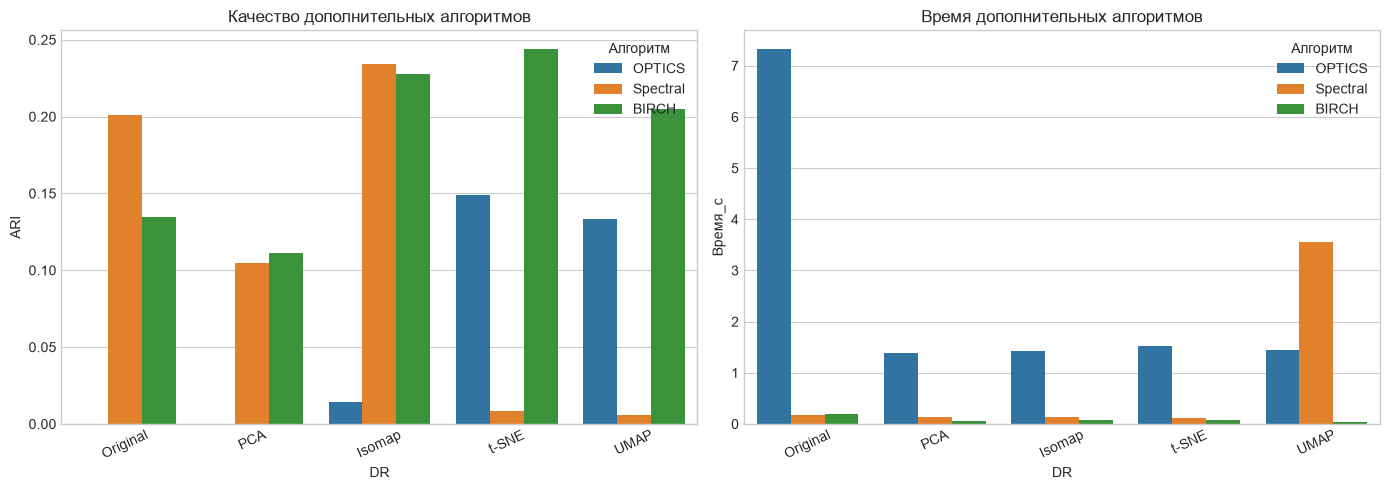

In [12]:
def extra_cluster_predict(name, X, n_clusters):
    if name == "OPTICS":
        return OPTICS(min_samples=12, xi=0.05, min_cluster_size=0.04).fit_predict(X)
    if name == "Spectral":
        return SpectralClustering(
            n_clusters=n_clusters, affinity="nearest_neighbors", n_neighbors=15,
            assign_labels="kmeans", random_state=RANDOM_STATE
        ).fit_predict(X)
    if name == "BIRCH":
        return Birch(n_clusters=n_clusters, threshold=0.5).fit_predict(X)
    raise ValueError(name)


extra_rows = []
for method in dr_methods:
    X_dr = representations[("Mice", method)]
    for algorithm in ("OPTICS", "Spectral", "BIRCH"):
        start = time.perf_counter()
        labels = extra_cluster_predict(algorithm, X_dr, n_classes)
        elapsed = time.perf_counter() - start
        row = ClusteringEvaluator.evaluate(X_dr, labels, y_own, algorithm, method, elapsed)
        row["Датасет"] = "Mice"
        extra_rows.append(row)

extra_results = pd.DataFrame(extra_rows)
results_df = pd.concat([baseline_results, extra_results], ignore_index=True)
display(extra_results.sort_values("ARI", ascending=False)[
    ["DR", "Алгоритм", "Кластеров", "Шум_%", "Silhouette", "ARI", "AMI", "V_measure", "Время_с"]
].style.format({"Шум_%": "{:.1f}", "Silhouette": "{:.3f}", "ARI": "{:.3f}",
                "AMI": "{:.3f}", "V_measure": "{:.3f}", "Время_с": "{:.3f}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=extra_results, x="DR", y="ARI", hue="Алгоритм", ax=axes[0], errorbar=None)
sns.barplot(data=extra_results, x="DR", y="Время_с", hue="Алгоритм", ax=axes[1], errorbar=None)
axes[0].set_title("Качество дополнительных алгоритмов")
axes[1].set_title("Время дополнительных алгоритмов")
for ax in axes: ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

## Анализ устойчивости к начальным условиям и бутстрэп

C:\Users\1\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\Users\1\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\Users\1\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\Users\1\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when

,DR,Алгоритм,Средний ARI между запусками,Стандартное отклонение ARI
0,PCA,KMeans,0.659,0.140
1,PCA,GMM,0.687,0.135
2,UMAP,KMeans,0.692,0.114
3,UMAP,GMM,0.682,0.123


Silhouette           ARI       
                    mean    std   mean    std
DR   Алгоритм                                
PCA  GMM           0.332  0.019  0.099  0.012
     KMeans        0.352  0.013  0.102  0.008
UMAP GMM           0.477  0.063  0.238  0.018
     KMeans        0.473  0.035  0.245  0.022

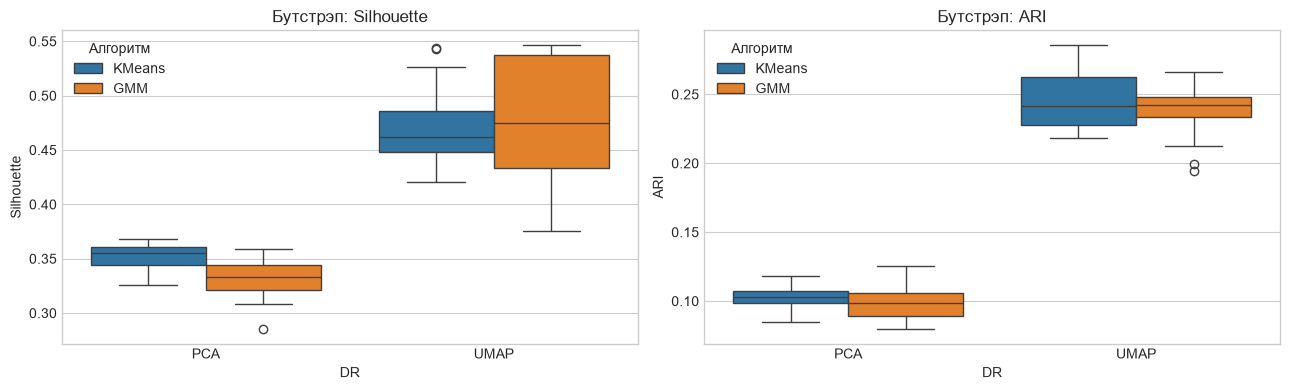

In [13]:
def labels_with_seed(algorithm, X, seed):
    if algorithm == "KMeans":
        return KMeans(n_clusters=n_classes, n_init=1, random_state=seed).fit_predict(X)
    return GaussianMixture(n_components=n_classes, n_init=1, random_state=seed).fit_predict(X)


rng = np.random.default_rng(RANDOM_STATE)
stability_rows = []
bootstrap_rows = []

for method in ("PCA", "UMAP"):
    X_dr = representations[("Mice", method)]
    for algorithm in ("KMeans", "GMM"):
        runs = [labels_with_seed(algorithm, X_dr, seed) for seed in range(15)]
        pairwise_ari = [adjusted_rand_score(runs[i], runs[j]) for i, j in combinations(range(15), 2)]
        stability_rows.append({
            "DR": method, "Алгоритм": algorithm,
            "Средний ARI между запусками": np.mean(pairwise_ari),
            "Стандартное отклонение ARI": np.std(pairwise_ari)
        })

        for b in range(20):
            idx = rng.choice(len(X_dr), len(X_dr), replace=True)
            X_boot, y_boot = X_dr[idx], y_own[idx]
            labels = labels_with_seed(algorithm, X_boot, b)
            bootstrap_rows.append({
                "DR": method, "Алгоритм": algorithm, "Итерация": b,
                "Silhouette": silhouette_score(X_boot, labels),
                "ARI": adjusted_rand_score(y_boot, labels)
            })

stability_df = pd.DataFrame(stability_rows)
bootstrap_df = pd.DataFrame(bootstrap_rows)
display(stability_df.style.format({"Средний ARI между запусками": "{:.3f}", "Стандартное отклонение ARI": "{:.3f}"}))
display(bootstrap_df.groupby(["DR", "Алгоритм"])[["Silhouette", "ARI"]].agg(["mean", "std"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=bootstrap_df, x="DR", y="Silhouette", hue="Алгоритм", ax=axes[0])
sns.boxplot(data=bootstrap_df, x="DR", y="ARI", hue="Алгоритм", ax=axes[1])
axes[0].set_title("Бутстрэп: Silhouette")
axes[1].set_title("Бутстрэп: ARI")
plt.tight_layout(); plt.show()

,DR,Алгоритм,Silhouette,ARI,AMI,V_measure,Комплексная_оценка
1,UMAP,GMM,0.530,0.247,0.429,0.436,0.846
2,UMAP,OPTICS,0.731,0.134,0.394,0.404,0.831
3,Isomap,Agglomerative,0.393,0.273,0.427,0.434,0.824
4,t-SNE,KMeans,0.430,0.245,0.427,0.433,0.808
5,Isomap,KMeans,0.419,0.254,0.418,0.425,0.806
6,Isomap,GMM,0.392,0.257,0.419,0.426,0.802
7,UMAP,KMeans,0.466,0.225,0.406,0.413,0.795
8,t-SNE,BIRCH,0.406,0.244,0.415,0.422,0.791
9,t-SNE,Agglomerative,0.412,0.238,0.409,0.416,0.781
10,Isomap,Spectral,0.388,0.234,0.401,0.408,0.769


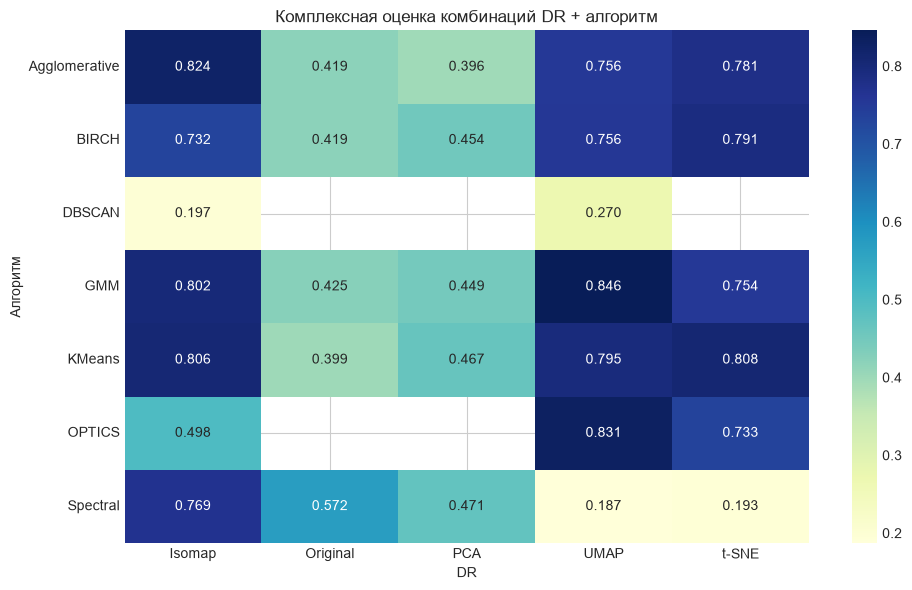

In [14]:
# Взвешенная комплексная оценка: все показатели приводятся к диапазону [0, 1].
ranking = results_df.dropna(subset=["Silhouette", "Calinski_Harabasz", "Davies_Bouldin"]).copy()
ranking["Inv_Davies_Bouldin"] = -ranking["Davies_Bouldin"]
score_columns = ["Silhouette", "Calinski_Harabasz", "Inv_Davies_Bouldin", "ARI", "AMI", "V_measure"]
normalized = MinMaxScaler().fit_transform(ranking[score_columns])
weights = np.array([0.20, 0.10, 0.10, 0.25, 0.15, 0.20])
ranking["Комплексная_оценка"] = normalized @ weights
ranking = ranking.sort_values("Комплексная_оценка", ascending=False).reset_index(drop=True)
ranking.index = ranking.index + 1

display(ranking[["DR", "Алгоритм", "Silhouette", "ARI", "AMI", "V_measure", "Комплексная_оценка"]]
        .head(15).style.format({"Silhouette": "{:.3f}", "ARI": "{:.3f}", "AMI": "{:.3f}",
                                "V_measure": "{:.3f}", "Комплексная_оценка": "{:.3f}"}))

pivot = ranking.pivot(index="Алгоритм", columns="DR", values="Комплексная_оценка")
plt.figure(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Комплексная оценка комбинаций DR + алгоритм")
plt.tight_layout(); plt.show()

## Итоги эксперимента

На наборе Mice лучший ARI в базовом сравнении получен для Agglomerative Clustering после Isomap: 0.273 при silhouette 0.393. Максимальная внутренняя оценка среди базовых комбинаций получена для GMM после UMAP (silhouette 0.530), но её ARI ниже — 0.247. Это наглядный пример расхождения внутренних и внешних критериев.

В исследовании гиперпараметров для Mice лучший результат KMeans дал Isomap с `n_neighbors=10`: ARI 0.254 и silhouette 0.419. t-SNE при `perplexity=30` дал ARI 0.245, а лучший проверенный UMAP по ARI использовал `n_neighbors=15`, `min_dist=0.5` и дал ARI 0.253. Следовательно, для этого набора нелинейное представление полезно, но результат чувствителен к параметрам.

Среди дополнительных алгоритмов лучший ARI показал BIRCH после t-SNE — 0.244. OPTICS иногда давал высокий silhouette только после исключения большого количества шума: например, после UMAP silhouette равен 0.731 при 42.6% шумовых объектов и ARI 0.134. Поэтому такую внутреннюю оценку нельзя рассматривать отдельно от доли шума и внешних метрик.

По 15 случайным инициализациям средний ARI между разбиениями находился примерно в диапазоне 0.66–0.69, то есть KMeans и GMM не полностью устойчивы. В бутстрэп-эксперименте UMAP дал более высокие средние ARI (около 0.24), чем PCA (около 0.10). По заданным весам первое место в комплексном рейтинге заняла комбинация UMAP + GMM с оценкой 0.846.

## Ответы на вопросы для обсуждения

1. **Как выбор DR влияет на качество кластеризации?** DR меняет геометрию пространства: может убрать шум и избыточность, но также потерять разделяющую информацию. Поэтому один алгоритм кластеризации даёт разные результаты на исходных данных, PCA, Isomap, t-SNE и UMAP. Выбирать представление следует по нескольким метрикам и устойчивости, а не только по внешнему виду проекции.

2. **Какие методы сохраняют локальную и глобальную структуру?** t-SNE в первую очередь сохраняет локальные соседства; UMAP также ориентирован на локальную топологию, но частично удерживает более крупную структуру. Isomap стремится сохранять геодезические расстояния на многообразии. PCA лучше остальных интерпретируется как сохранение глобальной линейной структуры и максимальной дисперсии.

3. **Почему t-SNE может плохо работать для кластеризации при хорошей визуализации?** Метод оптимизирует локальные вероятности соседства, искажает размеры кластеров и расстояния между «островами», чувствителен к perplexity и случайной инициализации. Визуально раздельные области поэтому не обязательно соответствуют реальным глобальным кластерам.

4. **Как понимать противоречия внутренних и внешних метрик?** Silhouette, Calinski–Harabasz и Davies–Bouldin оценивают геометрию найденных кластеров без знания классов. ARI, AMI и V-measure сравнивают разбиение с известной разметкой. Высокая внутренняя и низкая внешняя оценка означает, что геометрически компактные группы не совпадают с целевыми классами; это не ошибка метрики, а различие критериев.

5. **Когда выбирать линейные и нелинейные методы?** PCA подходит для быстрых, воспроизводимых и интерпретируемых преобразований, особенно при близкой к линейной структуре и необходимости применять обученное преобразование к новым объектам. UMAP, Isomap и t-SNE полезны при нелинейном многообразии; t-SNE чаще разумно использовать именно для разведочной визуализации.

6. **Как время выполнения влияет на production-выбор?** Важны не только время обучения, но и возможность преобразовать новые объекты, память, воспроизводимость и стоимость повторного подбора параметров. PCA обычно наиболее удобен в production; UMAP допускает `transform`, тогда как классический t-SNE не предоставляет естественного преобразования новых наблюдений.

7. **Какие метрики устойчивы к изменению числа кластеров?** Полностью независимых от числа кластеров метрик нет. Silhouette и Davies–Bouldin позволяют сравнивать разные числа кластеров, но имеют собственные предпочтения по форме и плотности. Calinski–Harabasz часто возрастает при дроблении. Внешние ARI и AMI корректируют случайные совпадения и полезны при наличии разметки; AMI особенно учитывает влияние числа групп.